
# Zomato Restaurant Review Sentiment Analysis

## Project Overview

This project focuses on analyzing Zomato restaurant reviews and building a machine learning model to classify customer feedback into Positive, Negative, and Neutral sentiments.

The project includes data merging, data cleaning, exploratory data analysis (EDA), feature engineering, text preprocessing, model development, and evaluation.

A Streamlit web application is also developed to allow users to enter restaurant reviews and predict their sentiment.

**Tools & Technologies:** Python, Pandas, NumPy, Matplotlib, Scikit-learn, Jupyter Notebook, Streamlit.



##  Importing Libraries

The required Python libraries are imported to perform data manipulation, numerical operations, data visualization, text preprocessing, and machine learning tasks.


In [1]:

import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)


In [2]:

reviews_df = pd.read_csv("C:\\Users\\Medhya Khatri\\OneDrive\\Desktop\\Labmentix\\Dataset\\Zomato Restaurant reviews.csv")

restaurants_df = pd.read_csv("C:\\Users\\Medhya Khatri\\OneDrive\\Desktop\\Labmentix\\Dataset\\Zomato Restaurant names and Metadata.csv")


In [3]:

print("Reviews Dataset Shape:", reviews_df.shape)
print("Restaurant Metadata Shape:", restaurants_df.shape)


Reviews Dataset Shape: (10000, 7)
Restaurant Metadata Shape: (105, 6)


In [4]:
print("Reviews Dataset Information:")
reviews_df.info()

print("\nRestaurant Metadata Information:")
restaurants_df.info()

Reviews Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 547.0+ KB

Restaurant Metadata Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-n

In [5]:
print("Missing Values in Reviews:")
display(reviews_df.isnull().sum())

print("\nMissing Values in Restaurant Metadata:")
display(restaurants_df.isnull().sum())

print("\nDuplicate Rows in Reviews:", reviews_df.duplicated().sum())
print("Duplicate Rows in Metadata:", restaurants_df.duplicated().sum())

Missing Values in Reviews:


Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64


Missing Values in Restaurant Metadata:


Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64


Duplicate Rows in Reviews: 36
Duplicate Rows in Metadata: 0



## Data Merging



In [6]:
merged_df = pd.merge(
    reviews_df,
    restaurants_df,
    left_on="Restaurant",
    right_on="Name",
    how="left",
    validate="many_to_one"
)

print("Merged Dataset Shape:", merged_df.shape)
display(merged_df.head())

Merged Dataset Shape: (10000, 13)


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"


In [7]:
print("Total Records:", len(merged_df))
print("Total Columns:", merged_df.shape[1])
print("Unmatched Restaurants:", merged_df["Name"].isna().sum())

Total Records: 10000
Total Columns: 13
Unmatched Restaurants: 0


In [8]:
# Inspect duplicate review records
duplicate_rows = merged_df[merged_df.duplicated(keep=False)]

print("Duplicate Records:", len(duplicate_rows))
display(duplicate_rows.head(10))

# Inspect records with all review details missing
missing_reviews = merged_df[
    merged_df[["Reviewer", "Review", "Rating", "Metadata", "Time"]]
    .isna()
    .all(axis=1)
]

print("Records with all review details missing:", len(missing_reviews))
display(missing_reviews.head())

Duplicate Records: 38


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Name,Links,Cost,Collections,Cuisines,Timings
8777,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8778,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8779,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8780,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8781,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8782,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8783,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8784,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8785,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8786,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM


Records with all review details missing: 38


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Name,Links,Cost,Collections,Cuisines,Timings
8777,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8778,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8779,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8780,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM
8781,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0,American Wild Wings,https://www.zomato.com/hyderabad/american-wild...,600,Food Hygiene Rated Restaurants in Hyderabad,"American, Fast Food, Salad, Burger",12 Noon to 4 AM


In [9]:
cleaned_df = merged_df.dropna(
    subset=["Reviewer", "Review", "Rating", "Metadata", "Time"],
    how="all"
).copy()

print("Original Dataset Shape:", merged_df.shape)
print("Cleaned Dataset Shape:", cleaned_df.shape)
print("Removed Records:", len(merged_df) - len(cleaned_df))

Original Dataset Shape: (10000, 13)
Cleaned Dataset Shape: (9962, 13)
Removed Records: 38


In [10]:
print("Remaining Duplicate Records:", cleaned_df.duplicated().sum())

Remaining Duplicate Records: 0


In [11]:
cleaned_df.isnull().sum()

Restaurant        0
Reviewer          0
Review            7
Rating            0
Metadata          0
Time              0
Pictures          0
Name              0
Links             0
Cost              0
Collections    5000
Cuisines          0
Timings         100
dtype: int64

In [12]:
missing_review_rows = cleaned_df[cleaned_df["Review"].isna()]

display(
    missing_review_rows[
        ["Restaurant", "Reviewer", "Rating", "Metadata", "Time", "Pictures"]
    ]
)

print("Missing Review Records:", len(missing_review_rows))
print("\nRatings in these records:")
print(missing_review_rows["Rating"].value_counts(dropna=False))

,Restaurant,Reviewer,Rating,Metadata,Time,Pictures
2360,Amul,Lakshmi Narayana,5,0 Reviews,7/29/2018 18:00,0
5799,Being Hungry,Surya,5,"4 Reviews , 4 Followers",7/19/2018 23:55,0
6449,Hyderabad Chefs,Madhurimanne97,5,1 Review,7/23/2018 16:29,0
6489,Hyderabad Chefs,Harsha,5,1 Review,7/8/2018 21:19,0
7954,Olive Garden,ARUGULLA PRAVEEN KUMAR,3,"1 Review , 1 Follower",8/9/2018 23:25,0
8228,Al Saba Restaurant,Suresh,5,1 Review,7/20/2018 22:42,0
8844,Domino's Pizza,Sayan Gupta,5,"2 Reviews , 2 Followers",8/9/2018 21:41,0


Missing Review Records: 7

Ratings in these records:
Rating
5    6
3    1
Name: count, dtype: int64


In [13]:
print(cleaned_df["Rating"].value_counts(dropna=False))

Rating
5       3832
4       2373
1       1735
3       1193
2        684
4.5       69
3.5       47
2.5       19
1.5        9
Like       1
Name: count, dtype: int64


In [14]:
display(
    cleaned_df[cleaned_df["Rating"] == "Like"][
        ["Restaurant", "Reviewer", "Review", "Rating", "Metadata"]
    ]
)

,Restaurant,Reviewer,Review,Rating,Metadata
7601,The Old Madras Baking Company,Dhanasekar Kannan,One of the best pizzas to try. It served with ...,Like,"12 Reviews , 21 Followers"


In [15]:
cleaned_df["Rating_Numeric"] = pd.to_numeric(
    cleaned_df["Rating"],
    errors="coerce"
)

In [16]:
print("Cost Data Type:", cleaned_df["Cost"].dtype)
print(cleaned_df["Cost"].unique())

Cost Data Type: object
['800' '1,300' '1,200' '1,500' '500' '300' '1,000' '350' '400' '1,600'
 '750' '550' '1,900' '450' '150' '1,400' '1,100' '600' '200' '900' '700'
 '1,700' '2,500' '850' '650' '1,800' '2,800' '1,750']


In [17]:
cleaned_df["Cost"] = (
    cleaned_df["Cost"]
    .str.replace(",", "", regex=False)
    .astype(int)
)

In [18]:
cleaned_df[["Rating_Numeric", "Cost", "Pictures"]].dtypes

Rating_Numeric    float64
Cost                int64
Pictures            int64
dtype: object

In [19]:
cleaned_df[["Rating_Numeric", "Cost", "Pictures"]].describe()

,Rating_Numeric,Cost,Pictures
count,9961.000000,9962.000000,9962.000000
mean,3.601044,871.531821,0.751456
std,1.483461,503.427308,2.574863
min,1.000000,150.000000,0.000000
25%,3.000000,500.000000,0.000000
50%,4.000000,700.000000,0.000000
75%,5.000000,1200.000000,0.000000
max,5.000000,2800.000000,64.000000


In [20]:
cleaned_df["Rating_Numeric"].value_counts().sort_index()

Rating_Numeric
1.0    1735
1.5       9
2.0     684
2.5      19
3.0    1193
3.5      47
4.0    2373
4.5      69
5.0    3832
Name: count, dtype: int64

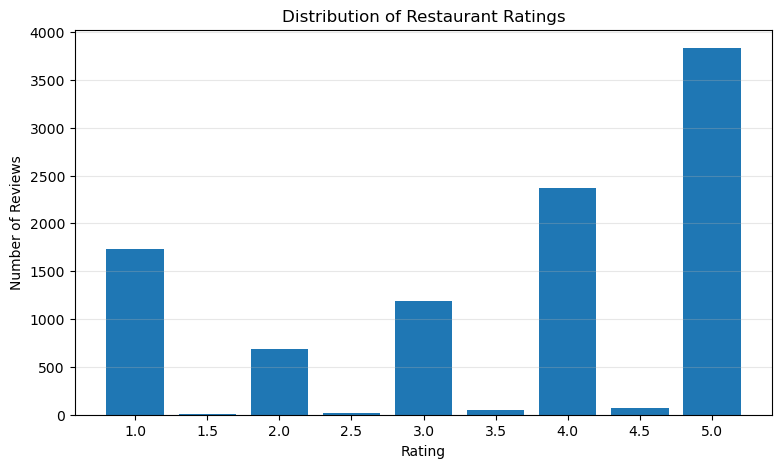

In [21]:
import matplotlib.pyplot as plt

rating_counts = cleaned_df["Rating_Numeric"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)
plt.show()

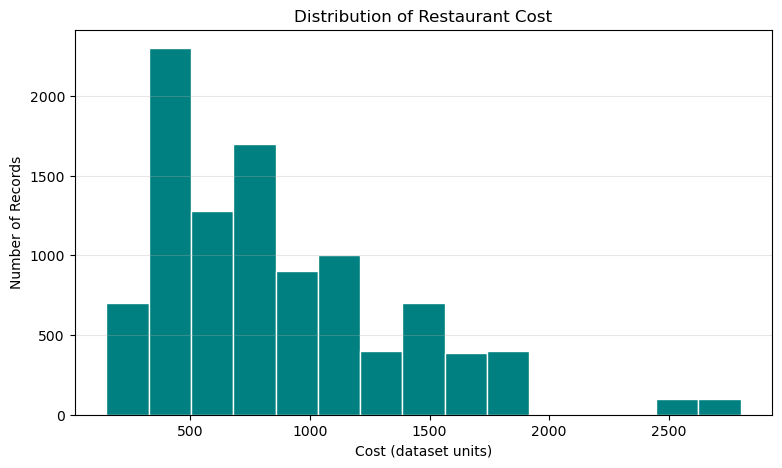

In [22]:
plt.figure(figsize=(9, 5))

plt.hist(
    cleaned_df["Cost"],
    bins=15,
    color="teal",
    edgecolor="white"
)

plt.title("Distribution of Restaurant Cost")
plt.xlabel("Cost (dataset units)")
plt.ylabel("Number of Records")
plt.grid(axis="y", alpha=0.3)

plt.show()

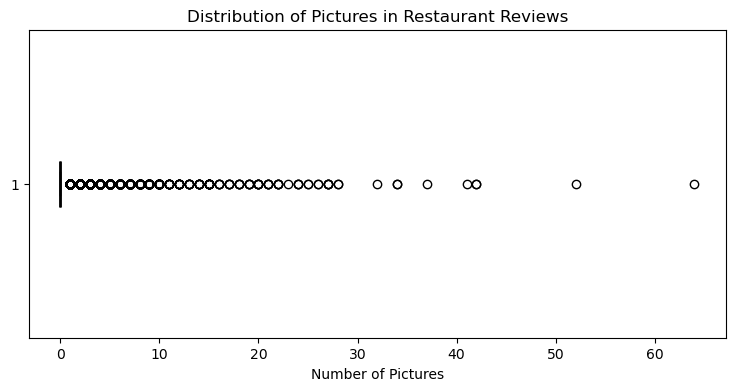

In [23]:
plt.figure(figsize=(9, 4))

plt.boxplot(
    cleaned_df["Pictures"],
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="mediumpurple"),
    medianprops=dict(color="black", linewidth=2)
)

plt.title("Distribution of Pictures in Restaurant Reviews")
plt.xlabel("Number of Pictures")
plt.show()

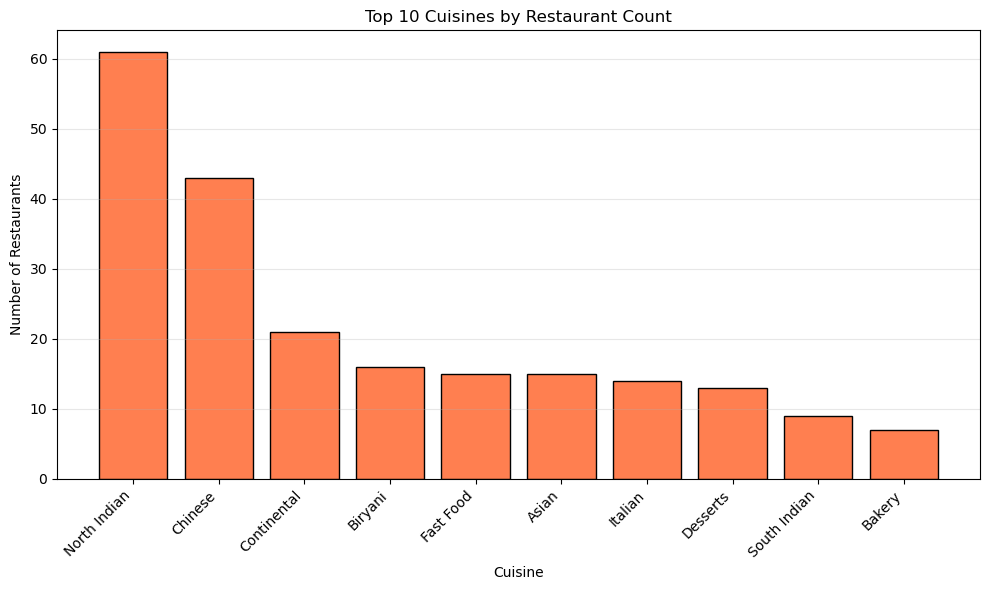

In [24]:
cuisine_counts = (
    restaurants_df["Cuisines"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.bar(
    cuisine_counts.index,
    cuisine_counts.values,
    color="coral",
    edgecolor="black"
)

plt.title("Top 10 Cuisines by Restaurant Count")
plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
restaurant_rating_summary = (
    cleaned_df.groupby("Restaurant")
    .agg(
        Average_Rating=("Rating_Numeric", "mean"),
        Review_Count=("Rating_Numeric", "count")
    )
    .query("Review_Count >= 20")
    .round(2)
    .sort_values("Average_Rating", ascending=False)
)

print("Top 10 Restaurants by Average Rating:")
display(restaurant_rating_summary.head(10))

print("Bottom 10 Restaurants by Average Rating:")
display(restaurant_rating_summary.tail(10))

Top 10 Restaurants by Average Rating:


,Average_Rating,Review_Count
Restaurant,,
AB's - Absolute Barbecues,4.88,100
B-Dubs,4.81,100
"3B's - Buddies, Bar & Barbecue",4.76,100
Paradise,4.70,100
Flechazo,4.66,100
The Indi Grill,4.60,100
Zega - Sheraton Hyderabad Hotel,4.45,100
Over The Moon Brew Company,4.34,100
Beyond Flavours,4.28,100


Bottom 10 Restaurants by Average Rating:


,Average_Rating,Review_Count
Restaurant,,
Desi Bytes,2.90,100
Club Rogue,2.88,100
KFC,2.85,100
Shree Santosh Dhaba Family Restaurant,2.83,100
The Chocolate Room,2.83,100
Mathura Vilas,2.82,100
Behrouz Biryani,2.82,100
Pakwaan Grand,2.71,100
Asian Meal Box,2.58,100


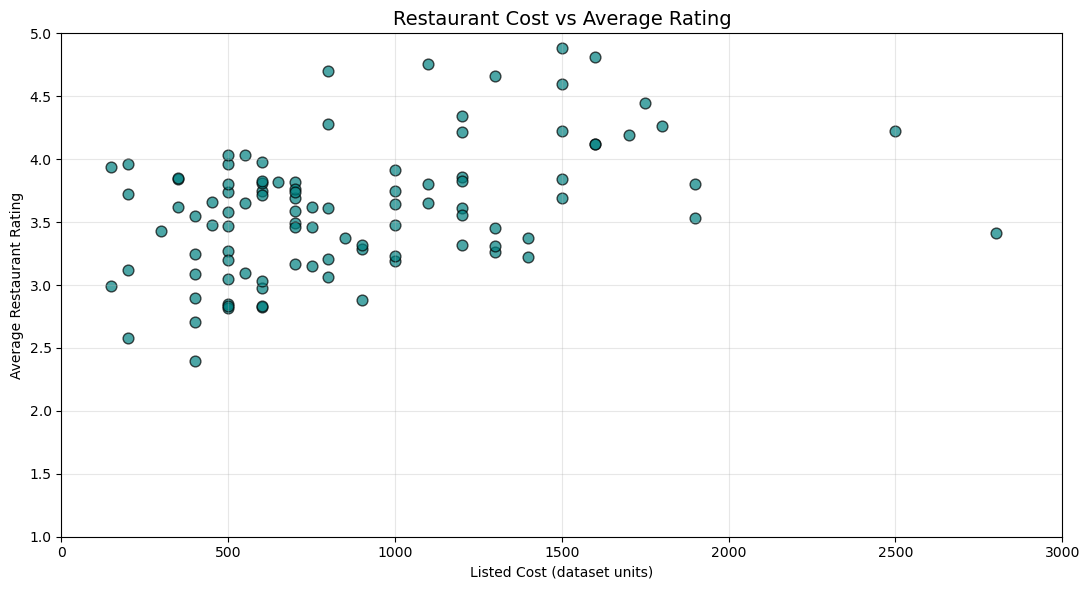

In [26]:
restaurant_level = (
    cleaned_df.groupby("Restaurant")
    .agg(
        Average_Rating=("Rating_Numeric", "mean"),
        Review_Count=("Rating_Numeric", "count"),
        Cost=("Cost", "first")
    )
    .reset_index()
)

plt.figure(figsize=(11, 6))

plt.scatter(
    restaurant_level["Cost"],
    restaurant_level["Average_Rating"],
    color="teal",
    alpha=0.7,
    s=60,
    edgecolor="black"
)

plt.title("Restaurant Cost vs Average Rating", fontsize=14)
plt.xlabel("Listed Cost (dataset units)")
plt.ylabel("Average Restaurant Rating")
plt.xlim(0, 3000)
plt.ylim(1, 5)
plt.xticks(range(0, 3001, 500))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
cleaned_df["Review_Length"] = cleaned_df["Review"].str.len()

print("Review Length Summary:")
display(cleaned_df["Review_Length"].describe().round(2))

print("Missing Review Lengths:", cleaned_df["Review_Length"].isna().sum())

Review Length Summary:


count    9955.00
mean      279.77
std       338.60
min         1.00
25%       144.00
50%       189.00
75%       321.00
max      5212.00
Name: Review_Length, dtype: float64

Missing Review Lengths: 7


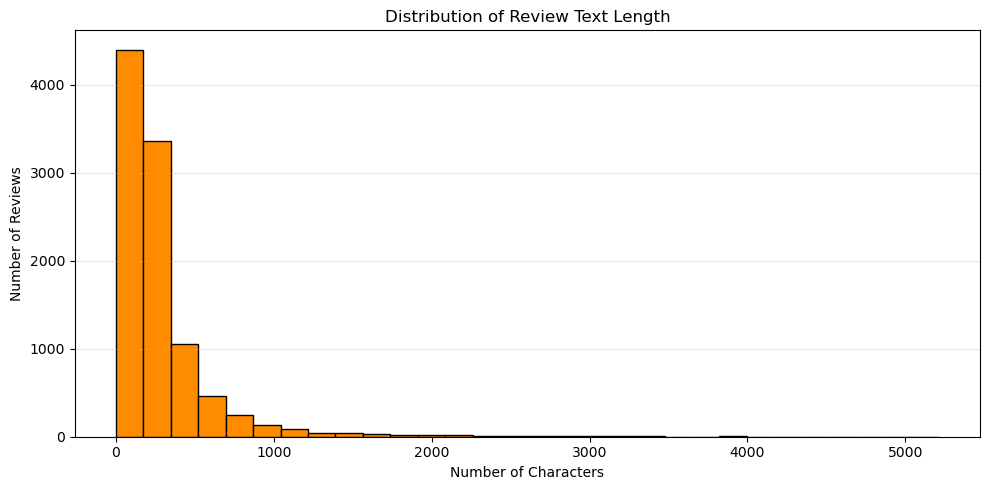

In [28]:
plt.figure(figsize=(10, 5))

plt.hist(
    cleaned_df["Review_Length"].dropna(),
    bins=30,
    color="darkorange",
    edgecolor="black"
)

plt.title("Distribution of Review Text Length")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
print("5 Shortest Reviews:")

display(
    cleaned_df[
        ["Review", "Review_Length", "Rating"]
    ]
    .dropna(subset=["Review"])
    .nsmallest(5, "Review_Length")
)

print("5 Longest Reviews:")

display(
    cleaned_df[
        ["Review", "Review_Length", "Rating"]
    ]
    .dropna(subset=["Review"])
    .nlargest(5, "Review_Length")
)

5 Shortest Reviews:


,Review,Review_Length,Rating
1583,😄,1.0,5
2090,D,1.0,5
3583,5,1.0,5
3736,4,1.0,4
3743,o,1.0,5


5 Longest Reviews:


,Review,Review_Length,Rating
9622,Hyderabadi Daawat as the name suggests has som...,5212.0,5
2130,A peaceful n quite place is something u want a...,5172.0,4
5216,Just the name of Biryani and Hyderabadis get h...,4610.0,4
9032,Arena eleven sports bar\n\nIPl is here and wha...,4119.0,4
836,Review :\n\nRecently we've received an invitat...,4104.0,5


In [30]:
short_reviews = (
    cleaned_df.loc[
        cleaned_df["Review_Length"] <= 5,
        ["Restaurant", "Review", "Review_Length", "Rating"]
    ]
    .sort_values("Review_Length")
)

print("Number of reviews with 5 or fewer characters:",
      len(short_reviews))

display(short_reviews)

Number of reviews with 5 or fewer characters: 436


,Restaurant,Review,Review_Length,Rating
2090,13 Dhaba,D,1.0,5
8379,GD's,y,1.0,5
5280,Biryanis And More,.,1.0,5
3583,Green Bawarchi Restaurant,5,1.0,5
6274,Shree Santosh Dhaba Family Restaurant,.,1.0,5
...,...,...,...,...
7499,Faasos,worst,5.0,1
2336,Amul,worst,5.0,1
5293,Biryanis And More,great,5.0,5
8975,Mohammedia Shawarma,super,5.0,5


In [31]:
short_text = cleaned_df.loc[
    cleaned_df["Review_Length"] <= 5, "Review"
].dropna().astype(str).str.strip()

short_review_categories = pd.Series({
    "Numeric-only": short_text.str.fullmatch(r"\d+").sum(),
    "Single-letter": short_text.str.fullmatch(r"[A-Za-z]").sum(),
    "Punctuation-or-emoji-only": short_text.str.fullmatch(r"[^\w\s]+").sum(),
    "Other short text": (
        ~short_text.str.fullmatch(r"\d+|[A-Za-z]|[^\w\s]+")
    ).sum()
})

display(short_review_categories)

Numeric-only                   4
Single-letter                  7
Punctuation-or-emoji-only     10
Other short text             415
dtype: int64

In [32]:
sentiment_df = cleaned_df.dropna(
    subset=["Rating_Numeric"]
).copy()

sentiment_df["Sentiment"] = pd.cut(
    sentiment_df["Rating_Numeric"],
    bins=[0, 2, 3.5, 5],
    labels=["Negative", "Neutral", "Positive"]
)

sentiment_counts = sentiment_df["Sentiment"].value_counts().reindex(
    ["Negative", "Neutral", "Positive"]
)

print("Sentiment Group Counts:")
display(sentiment_counts)

print("Sentiment Group Percentages:")
display((sentiment_counts / sentiment_counts.sum() * 100).round(2))

Sentiment Group Counts:


Sentiment
Negative    2428
Neutral     1259
Positive    6274
Name: count, dtype: int64

Sentiment Group Percentages:


Sentiment
Negative    24.38
Neutral     12.64
Positive    62.99
Name: count, dtype: float64

In [33]:
ml_candidate_df = sentiment_df.dropna(
    subset=["Review", "Sentiment"]
).copy()

ml_candidate_df["Review"] = (
    ml_candidate_df["Review"].astype(str).str.strip()
)

ml_candidate_df = ml_candidate_df[
    ml_candidate_df["Review"] != ""
].copy()

print("ML Candidate Dataset Shape:", ml_candidate_df.shape)

print("\nSentiment Distribution:")
display(ml_candidate_df["Sentiment"].value_counts())

print("\nSentiment Percentages:")
display(
    (ml_candidate_df["Sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)

ML Candidate Dataset Shape: (9954, 16)

Sentiment Distribution:


Sentiment
Positive    6268
Negative    2428
Neutral     1258
Name: count, dtype: int64


Sentiment Percentages:


Sentiment
Positive    62.97
Negative    24.39
Neutral     12.64
Name: proportion, dtype: float64

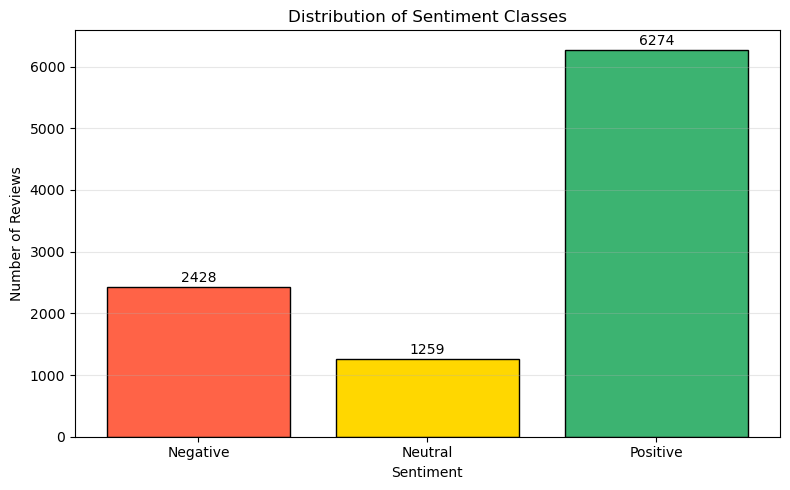

In [34]:
plt.figure(figsize=(8, 5))

plt.bar(
    sentiment_counts.index.astype(str),
    sentiment_counts.values,
    color=["tomato", "gold", "mediumseagreen"],
    edgecolor="black"
)

plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

for i, value in enumerate(sentiment_counts.values):
    plt.text(i, value + 80, str(value), ha="center")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

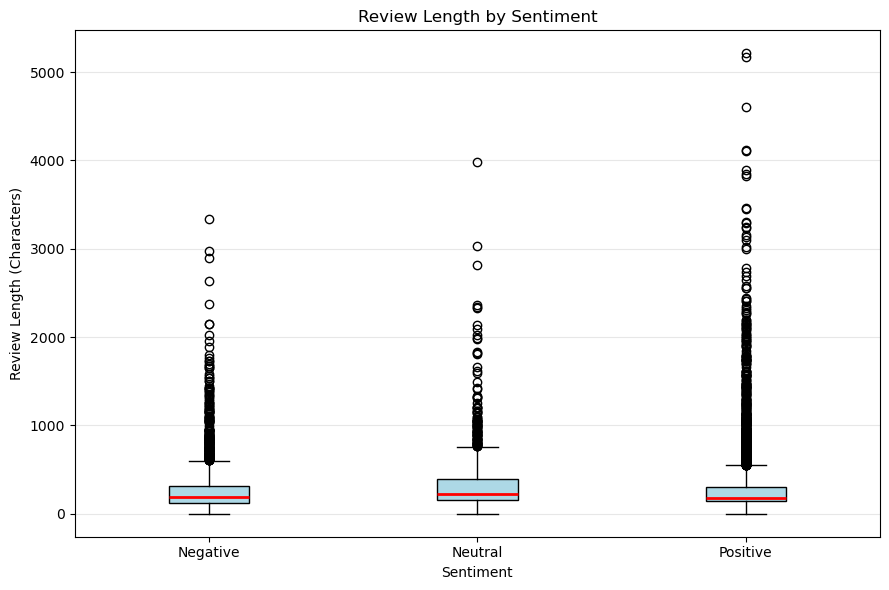

In [35]:
plt.figure(figsize=(9, 6))

plt.boxplot(
    [
        ml_candidate_df.loc[
            ml_candidate_df["Sentiment"] == sentiment,
            "Review_Length"
        ].dropna()
        for sentiment in ["Negative", "Neutral", "Positive"]
    ],
    tick_labels=["Negative", "Neutral", "Positive"],
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="red", linewidth=2)
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Review Length (Characters)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

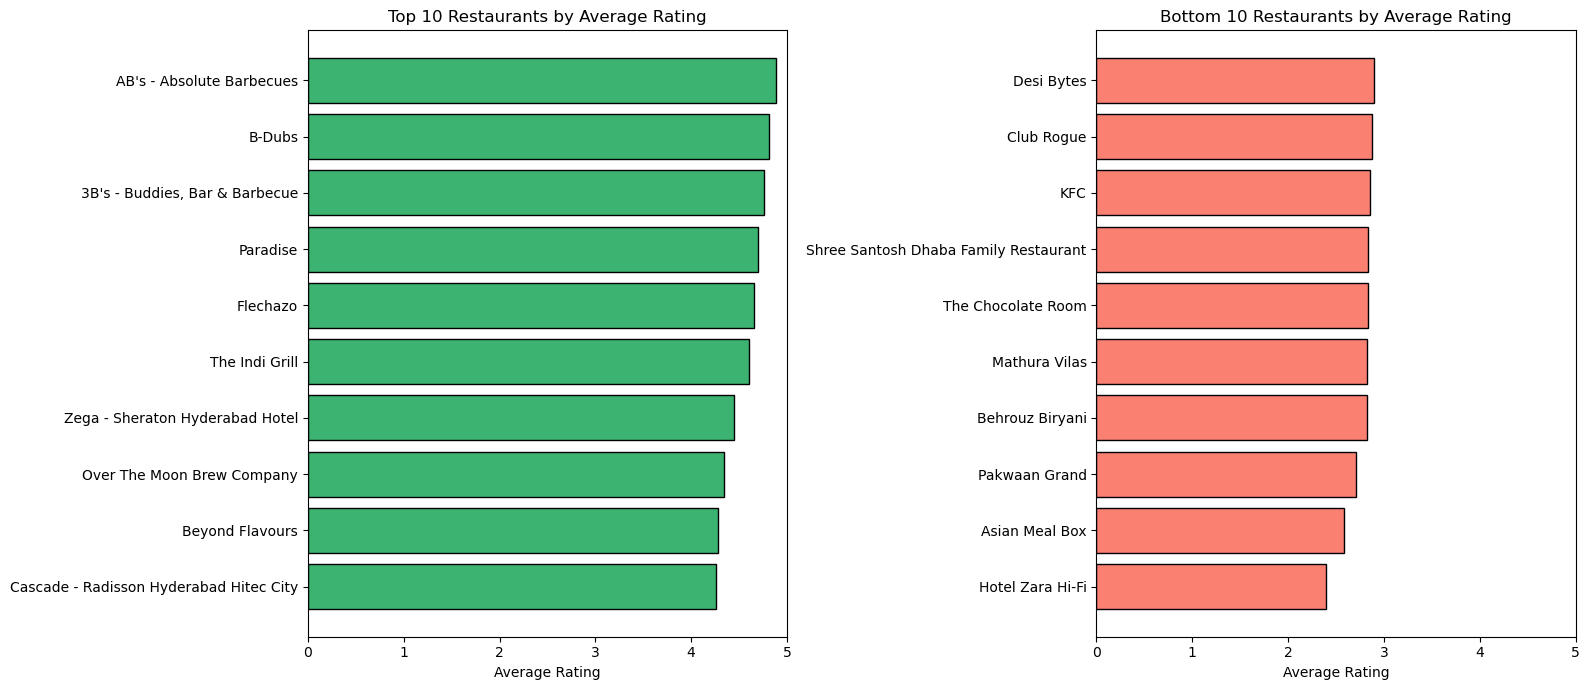

In [36]:
top_10 = restaurant_rating_summary.head(10)
bottom_10 = restaurant_rating_summary.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(
    top_10.index[::-1],
    top_10["Average_Rating"].values[::-1],
    color="mediumseagreen",
    edgecolor="black"
)
axes[0].set_title("Top 10 Restaurants by Average Rating")
axes[0].set_xlabel("Average Rating")
axes[0].set_xlim(0, 5)

axes[1].barh(
    bottom_10.index[::-1],
    bottom_10["Average_Rating"].values[::-1],
    color="salmon",
    edgecolor="black"
)
axes[1].set_title("Bottom 10 Restaurants by Average Rating")
axes[1].set_xlabel("Average Rating")
axes[1].set_xlim(0, 5)

plt.tight_layout()
plt.show()

In [37]:
cost_analysis = (
    cleaned_df.groupby("Restaurant")
    .agg(
        Average_Rating=("Rating_Numeric", "mean"),
        Cost=("Cost", "first")
    )
    .reset_index()
)

cost_analysis["Cost_Category"] = pd.qcut(
    cost_analysis["Cost"],
    q=3,
    labels=["Low Cost", "Medium Cost", "High Cost"]
)

cost_rating = (
    cost_analysis.groupby("Cost_Category", observed=False)
    .agg(
        Average_Rating=("Average_Rating", "mean"),
        Restaurant_Count=("Restaurant", "count")
    )
)

display(cost_rating.round(2))

,Average_Rating,Restaurant_Count
Cost_Category,,
Low Cost,3.38,33
Medium Cost,3.51,36
High Cost,3.95,31


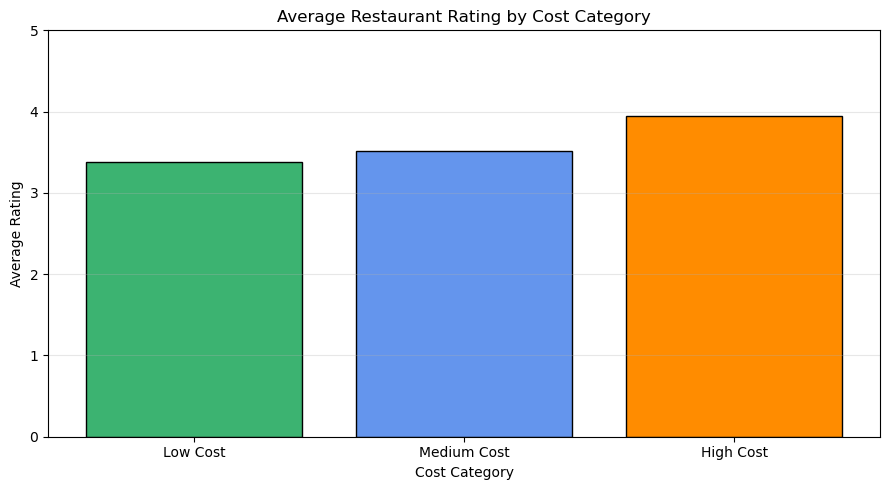

In [38]:
plt.figure(figsize=(9, 5))

plt.bar(
    cost_rating.index.astype(str),
    cost_rating["Average_Rating"],
    color=["mediumseagreen", "cornflowerblue", "darkorange"],
    edgecolor="black"
)

plt.title("Average Restaurant Rating by Cost Category")
plt.xlabel("Cost Category")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
cuisine_rating_df = (
    restaurant_level
    .merge(
        restaurants_df[["Name", "Cuisines"]],
        left_on="Restaurant",
        right_on="Name",
        how="left",
        validate="one_to_one"
    )
    .dropna(subset=["Cuisines"])
)

cuisine_rating_df["Cuisines"] = (
    cuisine_rating_df["Cuisines"].str.split(",")
)

cuisine_rating_df = cuisine_rating_df.explode("Cuisines")

cuisine_rating_df["Cuisines"] = (
    cuisine_rating_df["Cuisines"].str.strip()
)

cuisine_rating = (
    cuisine_rating_df.groupby("Cuisines")
    .agg(
        Average_Rating=("Average_Rating", "mean"),
        Restaurant_Count=("Restaurant", "nunique")
    )
    .query("Restaurant_Count >= 3")
    .sort_values("Average_Rating", ascending=False)
)

display(cuisine_rating.round(2))

,Average_Rating,Restaurant_Count
Cuisines,,
Mediterranean,4.55,5
European,4.38,4
American,3.93,6
Asian,3.92,14
Sushi,3.83,4
Continental,3.82,21
Kebab,3.79,6
Italian,3.78,14
Desserts,3.70,13


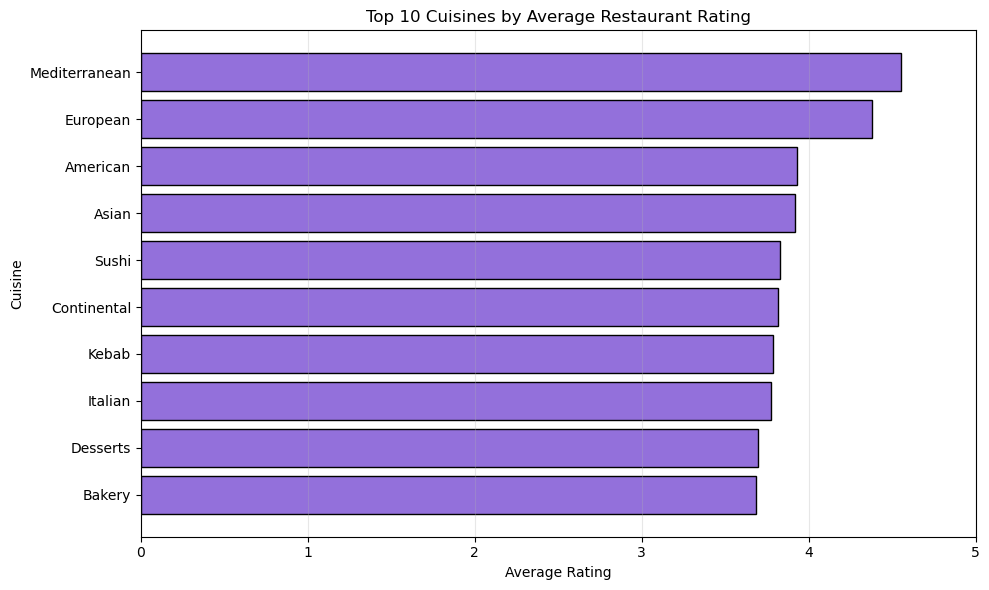

In [40]:
top_cuisines = cuisine_rating.head(10).sort_values("Average_Rating")

plt.figure(figsize=(10, 6))

plt.barh(
    top_cuisines.index,
    top_cuisines["Average_Rating"],
    color="mediumpurple",
    edgecolor="black"
)

plt.title("Top 10 Cuisines by Average Restaurant Rating")
plt.xlabel("Average Rating")
plt.ylabel("Cuisine")
plt.xlim(0, 5)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
picture_rating = (
    sentiment_df.assign(
        Picture_Status=np.where(
            sentiment_df["Pictures"] > 0,
            "With Pictures",
            "Without Pictures"
        )
    )
    .groupby("Picture_Status")
    .agg(
        Average_Rating=("Rating_Numeric", "mean"),
        Review_Count=("Rating_Numeric", "count")
    )
    .reindex(["Without Pictures", "With Pictures"])
)

display(picture_rating.round(2))

,Average_Rating,Review_Count
Picture_Status,,
Without Pictures,3.54,7978
With Pictures,3.86,1983


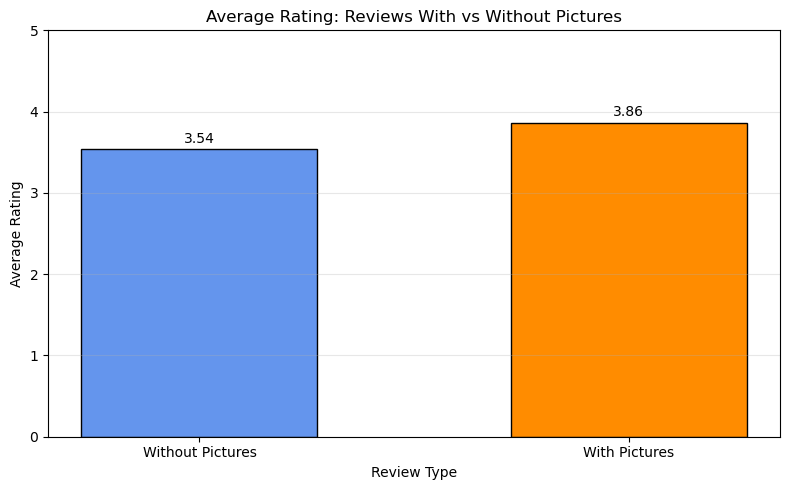

In [42]:
plt.figure(figsize=(8, 5))

plt.bar(
    picture_rating.index,
    picture_rating["Average_Rating"],
    color=["cornflowerblue", "darkorange"],
    edgecolor="black",
    width=0.55
)

plt.title("Average Rating: Reviews With vs Without Pictures")
plt.xlabel("Review Type")
plt.ylabel("Average Rating")
plt.ylim(0, 5)

for i, value in enumerate(picture_rating["Average_Rating"]):
    plt.text(i, value + 0.08, f"{value:.2f}", ha="center")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
print("Dataset Shape:", ml_candidate_df.shape)

print("\nColumn Names:")
print(ml_candidate_df.columns.tolist())

print("\nData Types:")
display(ml_candidate_df.dtypes.to_frame("Data Type"))

print("\nMissing Values:")
display(
    ml_candidate_df.isnull().sum()
    .to_frame("Missing Values")
    .query("`Missing Values` > 0")
)

Dataset Shape: (9954, 16)

Column Names:
['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures', 'Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings', 'Rating_Numeric', 'Review_Length', 'Sentiment']

Data Types:


,Data Type
Restaurant,object
Reviewer,object
Review,object
Rating,object
Metadata,object
Time,object
Pictures,int64
Name,object
Links,object
Cost,int64



Missing Values:


,Missing Values
Collections,4992
Timings,100


In [44]:
X = ml_candidate_df["Review"].copy()
y = ml_candidate_df["Sentiment"].copy()

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
display(y.value_counts())

Input Shape: (9954,)
Target Shape: (9954,)

Target Classes:


Sentiment
Positive    6268
Negative    2428
Neutral     1258
Name: count, dtype: int64

In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Sentiment Distribution:")
display(y_train.value_counts())

print("\nTesting Sentiment Distribution:")
display(y_test.value_counts())

Training Data: (7963,)
Testing Data: (1991,)

Training Sentiment Distribution:


Sentiment
Positive    5014
Negative    1942
Neutral     1007
Name: count, dtype: int64


Testing Sentiment Distribution:


Sentiment
Positive    1254
Negative     486
Neutral      251
Name: count, dtype: int64

In [46]:
print("Original Training Reviews:")

for review in X_train.head(5):
    print("\n", review)
    print("-" * 80)

Original Training Reviews:

 Had a very disappointing experience here today. We had been eyeing this place since long and planned our brunch to be had here. Loved the place, it was spacious and the ambiance was really good. The first thing I ordered was coffee but they were not serving any hot beverages. Next wanted to try pizza as they serve in different shapes but that too was unavailable. Did not felt like ordering anything after this. Highly disappointed.
--------------------------------------------------------------------------------

 An excellent get together place for a small crowd and their food choices are awesome .. we can enjoy some nice music and grrat food at best price :)
--------------------------------------------------------------------------------

 It's our default choice when we crave Chinese food and if we are around the Gachibowli area. The food tastes great and the fact that they are open all the way from lunch to dinner makes is a very viable option for a decen

In [47]:
for review, sentiment in zip(X_train.head(10), y_train.head(10)):
    print("Sentiment:", sentiment)
    print("Review:", review)
    print("-" * 80)

Sentiment: Negative
Review: Had a very disappointing experience here today. We had been eyeing this place since long and planned our brunch to be had here. Loved the place, it was spacious and the ambiance was really good. The first thing I ordered was coffee but they were not serving any hot beverages. Next wanted to try pizza as they serve in different shapes but that too was unavailable. Did not felt like ordering anything after this. Highly disappointed.
--------------------------------------------------------------------------------
Sentiment: Positive
Review: An excellent get together place for a small crowd and their food choices are awesome .. we can enjoy some nice music and grrat food at best price :)
--------------------------------------------------------------------------------
Sentiment: Positive
Review: It's our default choice when we crave Chinese food and if we are around the Gachibowli area. The food tastes great and the fact that they are open all the way from lunch 

In [48]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

X_train_clean = X_train.apply(clean_text)
X_test_clean = X_test.apply(clean_text)

print("Original Review:")
print(X_train.iloc[0])

print("\nCleaned Review:")
print(X_train_clean.iloc[0])

Original Review:
Had a very disappointing experience here today. We had been eyeing this place since long and planned our brunch to be had here. Loved the place, it was spacious and the ambiance was really good. The first thing I ordered was coffee but they were not serving any hot beverages. Next wanted to try pizza as they serve in different shapes but that too was unavailable. Did not felt like ordering anything after this. Highly disappointed.

Cleaned Review:
had a very disappointing experience here today. we had been eyeing this place since long and planned our brunch to be had here. loved the place, it was spacious and the ambiance was really good. the first thing i ordered was coffee but they were not serving any hot beverages. next wanted to try pizza as they serve in different shapes but that too was unavailable. did not felt like ordering anything after this. highly disappointed.


In [49]:
print("Empty reviews in training data:",
      (X_train_clean == "").sum())

print("Empty reviews in testing data:",
      (X_test_clean == "").sum())

print("\nMissing values in training data:",
      X_train_clean.isna().sum())

print("Missing values in testing data:",
      X_test_clean.isna().sum())

Empty reviews in training data: 0
Empty reviews in testing data: 0

Missing values in training data: 0
Missing values in testing data: 0


In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train_clean)
X_test_tfidf = tfidf.transform(X_test_clean)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (7963, 5000)
Testing TF-IDF shape: (1991, 5000)
Vocabulary size: 5000


In [51]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed.")

Model training completed.


In [52]:
y_pred = model.predict(X_test_tfidf)

print("Predictions generated successfully.")
print("\nFirst 10 actual labels:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())

Predictions generated successfully.

First 10 actual labels:
['Negative', 'Positive', 'Neutral', 'Positive', 'Negative', 'Positive', 'Positive', 'Positive', 'Positive', 'Negative']

First 10 predicted labels:
['Negative', 'Neutral', 'Neutral', 'Positive', 'Negative', 'Neutral', 'Positive', 'Positive', 'Positive', 'Negative']


In [53]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 81.67 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.80      0.84      0.82       486
     Neutral       0.39      0.50      0.44       251
    Positive       0.94      0.87      0.90      1254

    accuracy                           0.82      1991
   macro avg       0.71      0.74      0.72      1991
weighted avg       0.84      0.82      0.83      1991



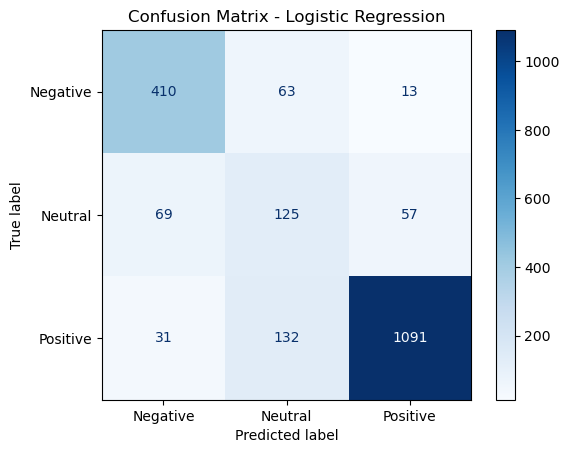

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [55]:
import os
import joblib

# Create Models folder
os.makedirs("Models", exist_ok=True)

# Save Logistic Regression model
joblib.dump(model, "Models/sentiment_model.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, "Models/tfidf_vectorizer.pkl")

print("Logistic Regression model saved successfully.")
print("TF-IDF vectorizer saved successfully.")

Logistic Regression model saved successfully.
TF-IDF vectorizer saved successfully.


In [56]:
import os
import joblib

print("Model exists:",
      os.path.exists("Models/sentiment_model.pkl"))

print("Vectorizer exists:",
      os.path.exists("Models/tfidf_vectorizer.pkl"))

# Load saved files
saved_model = joblib.load("Models/sentiment_model.pkl")
saved_tfidf = joblib.load("Models/tfidf_vectorizer.pkl")

print("\nBoth files loaded successfully.")

Model exists: True
Vectorizer exists: True

Both files loaded successfully.



# Conclusion

This project focused on analyzing Zomato restaurant reviews and developing a machine learning model for sentiment classification.

The two datasets were merged, cleaned, and explored to understand customer ratings, restaurant performance, review patterns, and other important insights.

A TF-IDF vectorizer was used to convert review text into numerical features, and Logistic Regression was implemented to classify reviews into Positive, Negative, and Neutral sentiments.

The model achieved **81.67% accuracy** on the test dataset. A Streamlit web application was also developed to allow users to enter restaurant reviews and receive sentiment predictions.

Through this project, practical experience was gained in data preprocessing, exploratory data analysis, feature engineering, machine learning, model evaluation, and application development.
